# Day 2 — Production Data Cleaning & Quality Audit Pipeline
**Project:** Oasis Infobyte Data Analytics Internship · Task Level 2 (Task 4)
**Focus:** Fix corrupted records, normalize numeric types, parse application sizes, resolve duplicates, clean user review text, and serialize validated datasets.


In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in sys.path
project_root = Path.cwd().parent if Path.cwd().name == 'Notebooks' else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_cleaning import (
    clean_playstore_apps,
    clean_user_reviews,
    parse_size_to_mb,
    generate_cleaning_audit
)

print(f"Project Root: {project_root}")


Project Root: C:\Users\Iba Zaidi\Desktop\OIBSIP\DataAnalytics-L2-GooglePlayStore


## 1. Raw Dataset Ingestion & Initial Profile
We begin by loading `googleplaystore.csv` and `googleplaystore_user_reviews.csv` to evaluate initial schema structure, missing value rates, and data anomalies.


In [2]:
data_dir = project_root / 'Data'
apps_raw = pd.read_csv(data_dir / 'googleplaystore.csv')
reviews_raw = pd.read_csv(data_dir / 'googleplaystore_user_reviews.csv')

print(f"Raw Play Store Apps: {apps_raw.shape[0]} rows, {apps_raw.shape[1]} columns")
print(f"Raw User Reviews:    {reviews_raw.shape[0]} rows, {reviews_raw.shape[1]} columns")


Raw Play Store Apps: 10841 rows, 13 columns
Raw User Reviews:    64295 rows, 5 columns


In [3]:
apps_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 2.2 MB


In [4]:
apps_raw.head(3)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up


## 2. Diagnosing Data Quality Issues
Let's inspect the most prominent issues in the raw apps dataset:
1. **Corrupted shifted rows**: Index 10472 where Category is missing, shifting numerical rating to 19.0.
2. **Data type mismatch**: `Reviews`, `Installs`, and `Price` are stored as string objects with symbols (`+`, `,`, `$`).
3. **App Size complexity**: Sizes are recorded with `M` (MB), `k` (KB), or `'Varies with device'`.
4. **Duplicate entries**: Multiple scraped records exist for the same app name with varying review counts.


In [5]:
# Check for ratings > 5.0 (corrupted rows)
corrupted_mask = apps_raw['Rating'] > 5.0
print(f"Number of records with Rating > 5.0: {corrupted_mask.sum()}")
apps_raw[corrupted_mask]


Number of records with Rating > 5.0: 1


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [6]:
# Check missing value counts in raw apps
missing_apps = apps_raw.isnull().sum()
missing_apps = missing_apps[missing_apps > 0]
print("Missing values in Apps:")
print(missing_apps)

# Check duplicate apps count
duplicate_apps_count = apps_raw.duplicated(subset=['App']).sum()
print(f"\nTotal duplicate app entries: {duplicate_apps_count}")


Missing values in Apps:
Rating            1474
Type                 1
Content Rating       1
Current Ver          8
Android Ver          3
dtype: int64

Total duplicate app entries: 1181


## 3. Visualizing Missing Data Patterns Before Cleaning

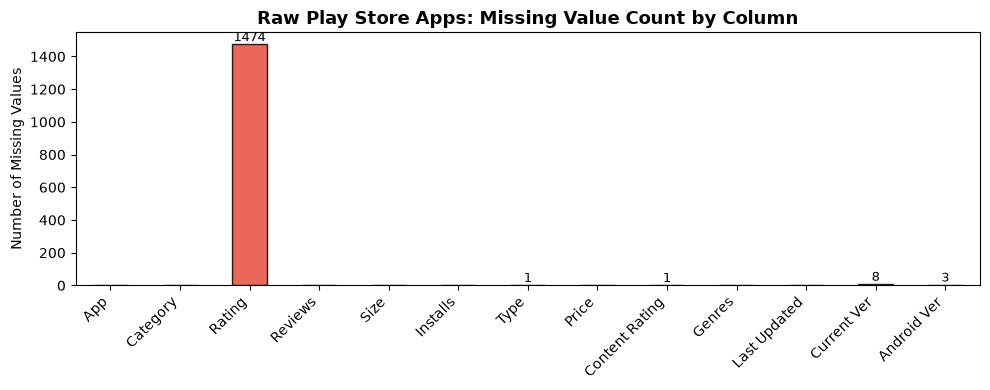

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
apps_raw.isnull().sum().plot(kind='bar', color='#e74c3c', ax=ax, edgecolor='black', alpha=0.85)
ax.set_title('Raw Play Store Apps: Missing Value Count by Column', fontsize=13, weight='bold')
ax.set_ylabel('Number of Missing Values')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(str(int(p.get_height())), (p.get_x() + p.get_width() / 2., p.get_height() + 20),
                    ha='center', fontsize=9)
plt.tight_layout()
plt.show()


## 4. Executing the Play Store Apps Cleaning Pipeline
Using our modular cleaning module `src.data_cleaning`, we execute:
- Dropping invalid shifted records (`Rating > 5.0`)
- Sanitizing and casting `Reviews` to `int64`
- Removing `+` and `,` from `Installs` and casting to `int64`
- Removing `$` from `Price` and casting to `float64`
- Parsing `Size` into `Size_MB` and computing category-median imputed size
- Standardizing `Type` (imputing based on price)
- Deduplicating apps keeping the highest review count instance


In [8]:
apps_clean = clean_playstore_apps(apps_raw, deduplicate=True)
print(f"Cleaned Apps Dataset Shape: {apps_clean.shape}")
print(f"Total Unique Apps: {apps_clean['App'].nunique()}")


Cleaned Apps Dataset Shape: (9659, 15)
Total Unique Apps: 9659


In [9]:
apps_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 9659 entries, 0 to 9658
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   App              9659 non-null   str           
 1   Category         9659 non-null   str           
 2   Rating           8196 non-null   float64       
 3   Reviews          9659 non-null   int64         
 4   Size             9659 non-null   str           
 5   Installs         9659 non-null   int64         
 6   Type             9659 non-null   str           
 7   Price            9659 non-null   float64       
 8   Content Rating   9659 non-null   str           
 9   Genres           9659 non-null   str           
 10  Last Updated     9659 non-null   datetime64[us]
 11  Current Ver      9651 non-null   str           
 12  Android Ver      9657 non-null   str           
 13  Size_MB          8431 non-null   float64       
 14  Size_MB_Imputed  9659 non-null   float64       
dty

In [10]:
apps_clean[['Rating', 'Reviews', 'Installs', 'Price', 'Size_MB', 'Size_MB_Imputed']].describe().T

,count,mean,std,min,25%,50%,75%,max
Rating,8196.0,4.173267e+00,5.362529e-01,1.000000,4.0,4.3,4.5,5.000000e+00
Reviews,9659.0,2.168041e+05,1.831430e+06,0.000000,25.0,969.0,29453.5,7.815831e+07
Installs,9659.0,7.798170e+06,5.376973e+07,0.000000,1000.0,100000.0,1000000.0,1.000000e+09
Price,9659.0,1.097231e+00,1.685162e+01,0.000000,0.0,0.0,0.0,4.000000e+02
Size_MB,8431.0,2.039807e+01,2.182896e+01,0.008301,4.6,12.0,28.0,1.000000e+02
Size_MB_Imputed,9659.0,1.952702e+01,2.075598e+01,0.010000,5.0,12.0,26.0,1.000000e+02


## 5. Cleaning User Reviews Dataset
The user reviews dataset contains user comments with sentiment labels and polarities.  
Key cleaning actions:
1. Drop records where `Translated_Review` is missing (over 26,000 null records).
2. Strip extraneous whitespace.
3. Eliminate duplicate review rows.
4. Validate `Sentiment_Polarity` in `[-1.0, 1.0]` and `Sentiment_Subjectivity` in `[0.0, 1.0]`.


In [11]:
reviews_clean = clean_user_reviews(reviews_raw)
print(f"Raw Reviews: {len(reviews_raw)} -> Clean Reviews: {len(reviews_clean)}")
print(f"Removed Null/Duplicate Reviews: {len(reviews_raw) - len(reviews_clean)}")


Raw Reviews: 64295 -> Clean Reviews: 29692
Removed Null/Duplicate Reviews: 34603


In [12]:
reviews_clean.head(4)

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
3,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


C:\Users\Iba Zaidi\AppData\Local\Temp\ipykernel_10988\2897617461.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=reviews_clean, x='Sentiment', palette='Set2', order=['Positive', 'Neutral', 'Negative'], ax=ax)


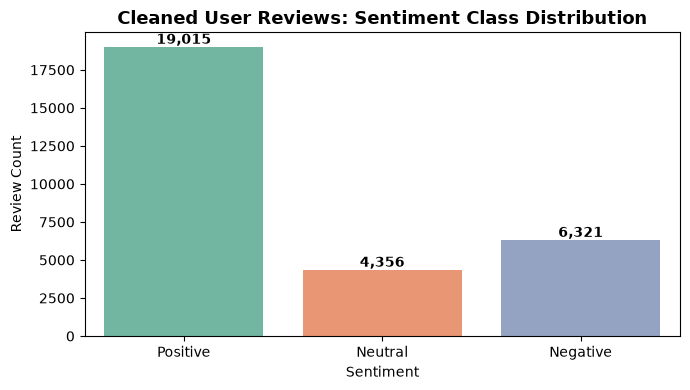

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=reviews_clean, x='Sentiment', palette='Set2', order=['Positive', 'Neutral', 'Negative'], ax=ax)
ax.set_title('Cleaned User Reviews: Sentiment Class Distribution', fontsize=13, weight='bold')
ax.set_ylabel('Review Count')
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() + 200),
                ha='center', fontsize=10, weight='bold')
plt.tight_layout()
plt.show()


## 6. Before vs. After Data Quality Comparison
A comparative summary validating the transformations performed on Day 2.


In [14]:
comparison_data = {
    'Metric': [
        'Apps Total Rows',
        'Apps Unique App Names',
        'Apps Installs Data Type',
        'Apps Reviews Data Type',
        'Apps Price Data Type',
        'Reviews Total Rows',
        'Reviews Missing Text Count'
    ],
    'Before Cleaning (Raw)': [
        f"{len(apps_raw):,}",
        f"{apps_raw['App'].nunique():,}",
        str(apps_raw['Installs'].dtype),
        str(apps_raw['Reviews'].dtype),
        str(apps_raw['Price'].dtype),
        f"{len(reviews_raw):,}",
        f"{reviews_raw['Translated_Review'].isnull().sum():,}"
    ],
    'After Cleaning (Day 1)': [
        f"{len(apps_clean):,}",
        f"{apps_clean['App'].nunique():,}",
        str(apps_clean['Installs'].dtype),
        str(apps_clean['Reviews'].dtype),
        str(apps_clean['Price'].dtype),
        f"{len(reviews_clean):,}",
        "0"
    ]
}

pd.DataFrame(comparison_data)


,Metric,Before Cleaning (Raw),After Cleaning (Day 1)
0,Apps Total Rows,"10,841","9,659"
1,Apps Unique App Names,"9,660","9,659"
2,Apps Installs Data Type,str,int64
3,Apps Reviews Data Type,str,int64
4,Apps Price Data Type,str,float64
5,Reviews Total Rows,"64,295","29,692"
6,Reviews Missing Text Count,"26,868",0


## 7. Exporting Cleaned Datasets
The pristine datasets are serialized to `Data/cleaned_googleplaystore.csv` and `Data/cleaned_user_reviews.csv` for seamless utilization in Day 2 EDA (Category, Ratings, and Size correlation analysis).


In [15]:
out_apps = data_dir / 'cleaned_googleplaystore.csv'
out_revs = data_dir / 'cleaned_user_reviews.csv'

apps_clean.to_csv(out_apps, index=False)
reviews_clean.to_csv(out_revs, index=False)

print(f"Successfully saved cleaned apps to: {out_apps} ({out_apps.stat().st_size / 1024:.1f} KB)")
print(f"Successfully saved cleaned reviews to: {out_revs} ({out_revs.stat().st_size / 1024:.1f} KB)")
print("Day 1 Data Cleaning & Validation Milestone Complete!")


Successfully saved cleaned apps to: C:\Users\Iba Zaidi\Desktop\OIBSIP\DataAnalytics-L2-GooglePlayStore\Data\cleaned_googleplaystore.csv (1171.8 KB)
Successfully saved cleaned reviews to: C:\Users\Iba Zaidi\Desktop\OIBSIP\DataAnalytics-L2-GooglePlayStore\Data\cleaned_user_reviews.csv (4795.3 KB)
Day 1 Data Cleaning & Validation Milestone Complete!
